# 🛸Evaluación Integradora – Parte 1
## Sistema Multicámara de Monitoreo Urbano y Detección Aérea con YOLOv8
**Asignatura:** Visión por Computadora — Licenciatura en Inteligencia Artificial  
**Institución:** Universidad Blas Pascal (UBP)  
**Integrantes:** Dennis Nelson Fernández (Legajo 189692) y Marcos Andrés Wamba Ferreyra (Legajo 190802)
**Repositorio Oficial:** https://github.com/fernandezdennis/vc-integrador-ubp/tree/main

---

> ℹ️ **NOTA IMPORTANTE PARA LA EVALUACIÓN (REPRODUCIBILIDAD "ZERO-TOUCH")**  
> Este cuaderno forma parte de un pipeline MLOps totalmente reproducible hospedado en **GitHub**.  
> **No es necesario montar Google Drive manualmente ni subir archivos locales.**  
>
> Para ejecutar y validar el trabajo completo de principio a fin:
> 1. Diríjase al menú superior: **Entorno de ejecución** → **Ejecutar todas** *(o presione `Ctrl + F9`)*.
> 2. La celda inicial clonará automáticamente los módulos de código desde GitHub, instalará las dependencias necesarias y descargará el conjunto de datos (`dataset_v2`), pesos del modelo y videos de prueba desde Google Drive.
> 3. Los resultados tabulares (`.csv`) y evidencias en video se generarán automáticamente en la carpeta de la sesión `/content/resultados`.

Implementa un pipeline de visión por computadora para la detección de objetos en una intersección urbana utilizando tres cámaras sincronizadas.

Los objetivos de esta primera etapa son:

- Sincronizar y analizar tres cámaras urbanas.
- Detectar personas y vehículos mediante YOLOv8.
- Identificar vehículos de color rojo.
- Generar registros estructurados de eventos.
- Unificar la información obtenida de las tres cámaras.
``

# 1. Preparación del entorno

En esta sección se instalan las librerías necesarias para ejecutar el proyecto.

Se utilizan principalmente:

- Ultralytics YOLOv8
- OpenCV
- NumPy
- Pandas
- Matplotlib

Estas herramientas permiten realizar la detección de objetos, análisis de color y generación de resultados.
`

In [ ]:
# ============================================================
# 1. CLONADO DEL REPOSITORIO Y DEPENDENCIAS
# ============================================================
import os
import sys
import yaml

# Reemplaza la URL con la de tu repositorio publico
REPO_URL = "https://github.com/fernandezdennis/vc-integrador-ubp"  # Reemplazar con tu URL de GitHub
REPO_DIR = "/content/proyecto_vc"

if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL} {REPO_DIR}

# Instalar librerias desde requirements.txt
!pip install -q -r {REPO_DIR}/requirements.txt

# Agregar la carpeta de scripts al PATH de Python
sys.path.append(os.path.join(REPO_DIR, "scripts"))

# ============================================================
# 2. DESCARGA AUTOMATICA DE DATOS Y PESOS (DRIVE + GDOWN)
# ============================================================
import gdown

DATA_DIR = "/content/data"
os.makedirs(DATA_DIR, exist_ok=True)

# ID exacto de tu archivo ZIP publico en Google Drive
DRIVE_ZIP_ID = "1LYbi_6j_vkI3yHYAu3ZWEFRjRxhW6PRt"
ZIP_PATH = os.path.join(DATA_DIR, "recursos_vc.zip")

if not os.path.exists(ZIP_PATH):
    print("Descargando dataset, pesos y videos desde Google Drive...")
    gdown.download(id=DRIVE_ZIP_ID, output=ZIP_PATH, quiet=False)
    print("Descomprimiendo archivos en /content/data...")
    !unzip -q {ZIP_PATH} -d {DATA_DIR}
    print("¡Recursos listos!")

# ============================================================
# 3. CONFIGURACION DINAMICA DE RUTAS Y DATA.YAML
# ============================================================
DATA_YAML = os.path.join(REPO_DIR, "configs", "data.yaml")
BEST_MODEL = os.path.join(DATA_DIR, "pesos", "best.pt")
YOLO_BASE = os.path.join(DATA_DIR, "pesos", "yolov8n.pt")
VIDEO_DRONE = os.path.join(DATA_DIR, "videos", "drone_ok.mp4")
RESULTADOS_DIR = "/content/resultados"

os.makedirs(RESULTADOS_DIR, exist_ok=True)

# Actualizar el campo path de data.yaml automaticamente
if os.path.exists(DATA_YAML):
    with open(DATA_YAML, "r") as f:
        config = yaml.safe_load(f)
    config["path"] = os.path.join(DATA_DIR, "dataset_v2")
    with open(DATA_YAML, "w") as f:
        yaml.dump(config, f)

print("Entorno local listo y rutas configuradas para reproduccion automatica.")

Cloning into '/content/proyecto_vc'...
remote: Enumerating objects: 26, done.
remote: Total 26 (delta 0), reused 0 (delta 0), pack-reused 26 (from 1)
Receiving objects: 100% (26/26), 47.32 MiB | 33.30 MiB/s, done.
Resolving deltas: 100% (2/2), done.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 2.8 MB/s eta 0:00:00
Descargando dataset, pesos y videos desde Google Drive...


Downloading...
From (original): https://drive.google.com/uc?id=1LYbi_6j_vkI3yHYAu3ZWEFRjRxhW6PRt
From (redirected): https://drive.google.com/uc?id=1LYbi_6j_vkI3yHYAu3ZWEFRjRxhW6PRt&confirm=t&uuid=f1e14325-a59e-4cd5-b6fa-cd581fca21d8
To: /content/data/recursos_vc.zip
100%|██████████| 2.98G/2.98G [00:30<00:00, 97.8MB/s]


Descomprimiendo archivos en /content/data...
¡Recursos listos!
Entorno local listo y rutas configuradas para reproduccion automatica.


# 2. Control origen de datos e importación de librerias

Muestra carpetas desde donde el trabajo pueda ser ejecutado tanto por los integrantes del proyecto como por los evaluadores.

In [ ]:
# ============================================================
# MUESTRA CARPETAS
# ============================================================

import os
import sys
from google.colab import drive, files

# Ruta base en tu Drive
BASE_DIR = "/content"

# Subcarpetas
VIDEO_DIR = os.path.join(BASE_DIR, "data/videos_prod")
SCRIPT_DIR = os.path.join(BASE_DIR, "proyecto_vc/scripts")

# Agregar scripts al path
sys.path.append(SCRIPT_DIR)
print("\n📁 Videos disponibles:")
print(os.listdir(VIDEO_DIR))

print("\n📁 Scripts disponibles:")
print(os.listdir(SCRIPT_DIR))

print("\n✔ Drive montado y rutas configuradas correctamente.")

print("\n✔ Archivos subidos y rutas configuradas correctamente.")
# ============================================================
# CONFIGURACIÓN FINAL
# ============================================================
print("\n🎯 Configuración completa. Puede ejecutar cualquiera de los pipelines:")



📁 Videos disponibles:
['calle_prod1min.mp4', 'piso3_prod.mp4', 'calle_prod.mp4', 'muni_prod.mp4', 'piso3_prod1min.mp4', 'muni_prod1min.mp4']

📁 Scripts disponibles:
['pipeline_calle.py', 'camara_rois_v2.py', 'editor_yolo.py', 'pipeline_piso3.py', 'pipeline_generico.py', 'utils_color.py', 'camara_rois.py', 'referencias_urbanas.py', 'pipeline_muni.py']

✔ Drive montado y rutas configuradas correctamente.

✔ Archivos subidos y rutas configuradas correctamente.

🎯 Configuración completa. Puede ejecutar cualquiera de los pipelines:


In [ ]:
import cv2
import numpy as np
import pandas as pd
from ultralytics import YOLO
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


# 3. Descripción de las cámaras utilizadas

El análisis se realiza sobre tres cámaras sincronizadas:

- **calle**: vista frontal a nivel de calle.
- **piso3**: vista elevada desde un edificio.
- **muni**: vista lateral municipal.

Los videos fueron normalizados finalmente a 15 FPS y posteriormente sincronizados mediante análisis visual y recorte temporal con FFmpeg.

(Alternativa para probar con videos de 10 minutos cuya ejecucion dura aprox.25 minutos o de 1 minuto para las pruebas)

En `FRAME_TO_SHOW` seleccionamos a gusto un frame para obtener evidencia.

In [ ]:
#Alternativa para probar con videos de 10 minutos o de 1 minuto para las pruebas
USE_SHORT_VIDEOS = True

if USE_SHORT_VIDEOS:
    VIDEO_CALLE = os.path.join(VIDEO_DIR, "calle_prod1min.mp4")
    VIDEO_PISO3 = os.path.join(VIDEO_DIR, "piso3_prod1min.mp4")
    VIDEO_MUNI  = os.path.join(VIDEO_DIR, "muni_prod1min.mp4")
    FRAME_TO_SHOW = 196 # Elegimos este frame representativo en video corto
else:
    VIDEO_CALLE = os.path.join(VIDEO_DIR, "calle_prod.mp4")
    VIDEO_PISO3 = os.path.join(VIDEO_DIR, "piso3_prod.mp4")
    VIDEO_MUNI  = os.path.join(VIDEO_DIR, "muni_prod.mp4")
    FRAME_TO_SHOW = 1892 # Elegimos este frame representativo en video largo

# 4. Configuración operativa y escenario de despliegue

Durante la etapa inicial de desarrollo, los videos fueron normalizados a **30 FPS** con el objetivo de facilitar las tareas de sincronización temporal y validación visual entre las distintas cámaras.

Posteriormente, y a partir de las observaciones realizadas por el docente durante la revisión del proyecto, se reconsideraron los parámetros de operación pensando en una posible implementación real del sistema.

## Frecuencia de procesamiento propuesta

Se adoptó una configuración de:

- Resolución: **1280 × 720 píxeles**
- Frecuencia: **15 FPS**

La elección de 15 FPS permite reducir aproximadamente un 50% la carga computacional respecto de 30 FPS, manteniendo una calidad suficiente para:

- detección de vehículos,
- clasificación de objetos,
- identificación de color,
- tracking de trayectorias,
- análisis de tránsito urbano.

Dado que el objetivo del proyecto no requiere reconocimiento facial ni análisis de movimientos de alta velocidad, se considera que 15 FPS representa un equilibrio adecuado entre rendimiento y precisión.

## Escenario de referencia para una implementación municipal

Se consideró un escenario compuesto por:

- 5 intersecciones urbanas.
- 3 cámaras por intersección.
- 15 cámaras procesadas de forma simultánea.

Para un despliegue de estas características se propone una estación de procesamiento con la siguiente configuración mínima:

| Componente | Configuración propuesta |
|------------|-------------------------|
| CPU | AMD Ryzen 9 9950X o equivalente |
| Memoria RAM | 64 GB DDR5 |
| GPU | NVIDIA RTX 4080 Super |
| Almacenamiento | SSD NVMe 2 TB |
| Sistema Operativo | Ubuntu Server LTS |

Esta infraestructura permitiría ejecutar los modelos de visión por computadora sobre múltiples cámaras urbanas en forma simultánea, manteniendo capacidad de crecimiento para futuras funcionalidades de tracking e integración multi-cámara.

# 5. Detección de objetos con YOLOv8

Se utiliza el modelo YOLOv8 para detectar:

- Personas
- Automóviles
- Motocicletas
- Bicicletas
- Camiones

Para cada detección se registran:

- Clase detectada
- Timestamp
- Bounding Box normalizado
- Cámara de origen

In [ ]:
from pipeline_calle import procesar_calle
from pipeline_piso3 import procesar_piso3
from pipeline_muni import procesar_muni

RESULTADOS_DIR = os.path.join(BASE_DIR, "resultados")
os.makedirs(RESULTADOS_DIR, exist_ok=True)

CSV_CALLE = os.path.join(RESULTADOS_DIR, "eventos_calle.csv")
CSV_PISO3 = os.path.join(RESULTADOS_DIR, "eventos_piso3.csv")
CSV_MUNI = os.path.join(RESULTADOS_DIR, "eventos_muni.csv")
CSV_TOTAL = os.path.join(RESULTADOS_DIR, "eventos_total.csv")

# 6. Identificación de vehículos rojos

Además de la detección de objetos, se implementa un análisis de color basado en HSV.

El criterio utilizado combina:

- Porcentaje de píxeles rojos.
- Distribución espacial del rojo (spread).

Este enfoque permite evitar falsos positivos producidos por luces de freno o reflejos.

In [ ]:
from utils_color import is_red_vehicle # Import the missing function

# 7. Procesamiento de las tres cámaras

Cada cámara es procesada individualmente mediante un pipeline común.

Como resultado se genera un archivo CSV por cámara con todos los eventos detectados.

Posteriormente los tres conjuntos de datos se unifican para facilitar el análisis global.

In [ ]:
procesar_calle(VIDEO_CALLE,CSV_CALLE)
procesar_piso3(VIDEO_PISO3, CSV_PISO3)
procesar_muni(VIDEO_MUNI, CSV_MUNI)

df_calle = pd.read_csv(CSV_CALLE)
df_piso3 = pd.read_csv(CSV_PISO3)
df_muni = pd.read_csv(CSV_MUNI)

Se han truncado las últimas 5000 líneas del flujo de salida.
ROI HIT muni contenedor_obra 0.782884418964386 0.4860561490058899
EXCLUIDO -> muni car (0.783,0.486)
VERIFICANDO muni car xc=0.447 yc=0.635
VERIFICANDO muni car xc=0.449 yc=0.629
VERIFICANDO muni car xc=0.633 yc=0.461
ROI HIT muni monumento_san_martin 0.6329048275947571 0.4613416790962219
EXCLUIDO -> muni car (0.633,0.461)
VERIFICANDO muni car xc=0.924 yc=0.524
VERIFICANDO muni car xc=0.922 yc=0.499
VERIFICANDO muni car xc=0.923 yc=0.514

0: 384x640 14 cars, 127.0ms
Speed: 5.9ms preprocess, 127.0ms inference, 1.1ms postprocess per image at shape (1, 3, 384, 640)
VERIFICANDO muni car xc=0.381 yc=0.616
VERIFICANDO muni car xc=0.457 yc=0.712
VERIFICANDO muni car xc=0.619 yc=0.796
VERIFICANDO muni car xc=0.783 yc=0.790
VERIFICANDO muni car xc=0.909 yc=0.633
VERIFICANDO muni car xc=0.516 yc=0.523
VERIFICANDO muni car xc=0.863 yc=0.616
VERIFICANDO muni car xc=0.447 yc=0.634
VERIFICANDO muni car xc=0.893 yc=0.515
VERIFICANDO muni ca

# 8. Integración multi-cámara

Los eventos obtenidos de cada cámara se combinan en un único DataFrame denominado **df_total**.

La columna *camera* permite identificar el origen de cada detección.

Este conjunto de datos constituye la base de trabajo para los análisis posteriores.

In [ ]:
df_total = pd.concat(
    [df_calle, df_piso3, df_muni],
    ignore_index=True
)
#Guardamos el csv inmediatamente
df_total.to_csv(
os.path.join(RESULTADOS_DIR, "eventos_total.csv"),
index=False
)

# 9. Evidencia visual de las detecciones

Se selecciona un frame específico y se visualiza simultáneamente en las tres cámaras.

Sobre cada imagen se dibujan:

- Bounding Boxes detectadas por YOLO.
- Clasificación del objeto.
- Vehículos rojos identificados mediante el módulo de color.

Las imágenes resultantes también se almacenan automáticamente en la carpeta **evidencia**.

In [ ]:
#Crear carpeta evidencia
EVIDENCIA_DIR = os.path.join(BASE_DIR, "evidencia")
os.makedirs(EVIDENCIA_DIR, exist_ok=True)

<IPython.core.display.Javascript object>


0: 384x640 1 person, 3 cars, 226.1ms
Speed: 14.0ms preprocess, 226.1ms inference, 1.6ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 10 cars, 1 bus, 130.6ms
Speed: 5.2ms preprocess, 130.6ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 2 persons, 6 cars, 1 bus, 135.9ms
Speed: 4.3ms preprocess, 135.9ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)


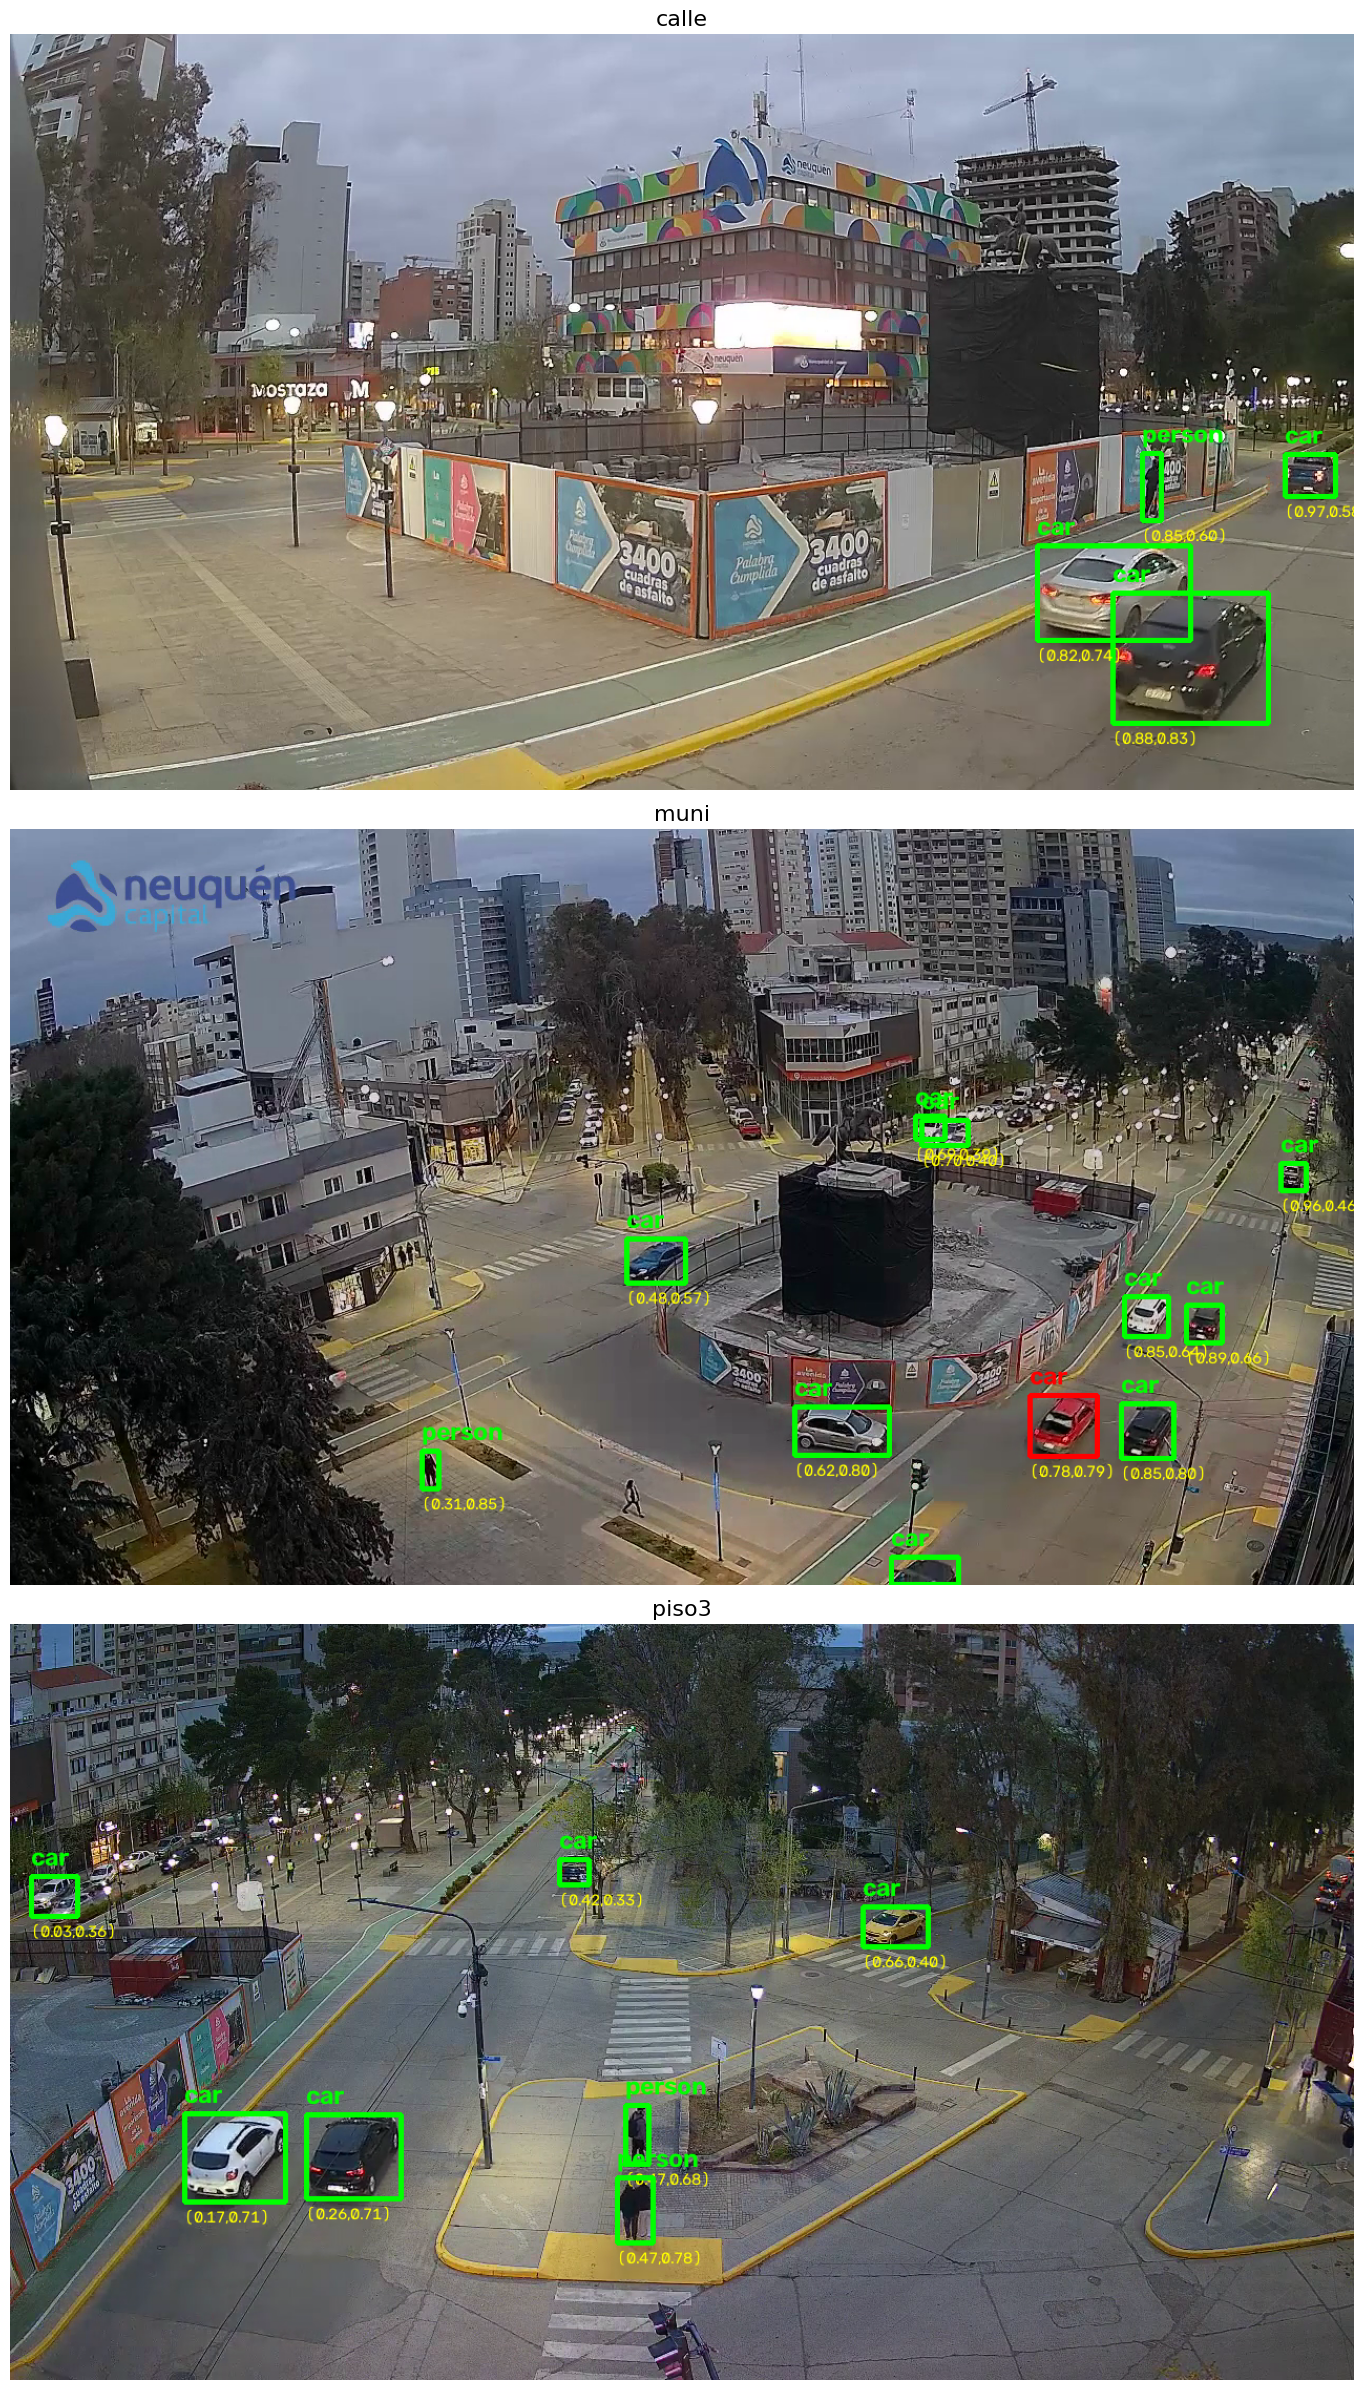

✅ PNG guardados en: /content/evidencia


In [ ]:
import cv2
import matplotlib.pyplot as plt
import os
from ultralytics import YOLO
from camara_rois import CAMERA_CONFIG
from google.colab import output

# Desactivar la barra de scroll vertical de la salida en Colab
output.no_vertical_scroll()

def inside_exclusion_zone(camera_name, xc, yc):
    """
    Checks if a given (xc, yc) point is inside any exclusion zone for a specific camera.
    Args:
        camera_name (str): The name of the camera (e.g., 'muni', 'piso3', 'calle').
        xc (float): Normalized x-coordinate of the object's center.
        yc (float): Normalized y-coordinate of the object's center.
    Returns:
        bool: True if the point is inside an exclusion zone, False otherwise.
    """
    if camera_name in CAMERA_CONFIG and "exclusion_zones" in CAMERA_CONFIG[camera_name]:
        for zone in CAMERA_CONFIG[camera_name]["exclusion_zones"]:
            x1, y1, x2, y2 = zone["x1"], zone["y1"], zone["x2"], zone["y2"]
            if x1 <= xc <= x2 and y1 <= yc <= y2:
                return True
    return False

# Se corrigen las rutas para usar directamente las variables absolutas ya configuradas
videos = {
    "calle": VIDEO_CALLE,
    "muni": VIDEO_MUNI,
    "piso3": VIDEO_PISO3
}

# Initialize the YOLO model
model = YOLO('yolov8n.pt')

# Define CLASSES_INTERES
CLASSES_INTERES = ["person", "car", "motorcycle", "bus", "truck", "bicycle"]

# Creamos la figura con un tamaño expandido para ver las 3 imágenes completas y grandes
fig, axes = plt.subplots(3, 1, figsize=(16, 24))
for ax, (camera_name, video_path) in zip(axes, videos.items()):

    cap = cv2.VideoCapture(video_path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_TO_SHOW)
    ret, frame = cap.read()
    cap.release()

    if not ret:
        ax.set_title(f"{camera_name} - Frame no encontrado")
        ax.axis("off")
        continue

    h, w, _ = frame.shape
    results = model(frame)[0]

    for box in results.boxes:
        cls_idx = int(box.cls[0])
        clase_nombre = model.names[cls_idx]

        if clase_nombre not in CLASSES_INTERES:
            continue

        xc, yc, bw, bh = box.xywhn[0].tolist()
        # excluir zonas prohibidas
        if inside_exclusion_zone(camera_name, xc, yc):
            continue
        x_center = int(xc * w)
        y_center = int(yc * h)

        box_w = int(bw * w)
        box_h = int(bh * h)

        x1 = max(0, x_center - box_w // 2)
        y1 = max(0, y_center - box_h // 2)
        x2 = min(w, x_center + box_w // 2)
        y2 = min(h, y_center + box_h // 2)

        roi = frame[y1:y2, x1:x2]
        is_red = False

        if clase_nombre in ["car", "motorcycle", "bicycle", "truck"]:
            is_red = is_red_vehicle(
                roi,
                ratio_threshold=0.12,
                spread_threshold=0.25
            )

        color = (0, 255, 0)
        if is_red:
            color = (0, 0, 255)

        cv2.rectangle(frame, (x1, y1), (x2, y2), color, 3) # Grosor de línea aumentado para mejor visualización

        cv2.putText(
            frame,
            clase_nombre,
            (x1, y1 - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            color,
            2
        )
        cv2.putText(
            frame,
            f"({xc:.2f},{yc:.2f})",
            (x1, y2 + 20),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0,255,255),
            1
        )

    # =========================================
    # GUARDAR PNG EN EVIDENCIA
    # =========================================
    png_name = f"{camera_name}_frame_{FRAME_TO_SHOW}.png"
    cv2.imwrite(
         os.path.join(EVIDENCIA_DIR, png_name),
         frame
    )

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    ax.imshow(rgb)
    ax.set_title(camera_name, fontsize=16)
    ax.axis("off")

plt.tight_layout()
plt.show()
print(f"✅ PNG guardados en: {EVIDENCIA_DIR}")

In [ ]:
import cv2
import os

for name, path in videos.items():
    exists = os.path.exists(path)
    print(f"Cámara: {name}")
    print(f"  - Ruta: {path}")
    print(f"  - ¿Existe el archivo?: {exists}")
    if exists:
        print(f"  - Tamaño: {os.path.getsize(path) / (1024*1024):.2f} MB")
        cap = cv2.VideoCapture(path)
        opened = cap.isOpened()
        print(f"  - ¿Abrió con OpenCV?: {opened}")
        if opened:
            total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            print(f"  - Total de frames disponibles: {total_frames}")
        cap.release()
    print("-" * 40)

Cámara: calle
  - Ruta: /content/data/videos_prod/calle_prod1min.mp4
  - ¿Existe el archivo?: True
  - Tamaño: 8.10 MB
  - ¿Abrió con OpenCV?: True
  - Total de frames disponibles: 652
----------------------------------------
Cámara: muni
  - Ruta: /content/data/videos_prod/muni_prod1min.mp4
  - ¿Existe el archivo?: True
  - Tamaño: 10.31 MB
  - ¿Abrió con OpenCV?: True
  - Total de frames disponibles: 652
----------------------------------------
Cámara: piso3
  - Ruta: /content/data/videos_prod/piso3_prod1min.mp4
  - ¿Existe el archivo?: True
  - Tamaño: 7.66 MB
  - ¿Abrió con OpenCV?: True
  - Total de frames disponibles: 652
----------------------------------------


In [ ]:
import os

# Path to camara_rois.py (using SCRIPT_DIR defined previously)
camara_rois_path = os.path.join(SCRIPT_DIR, 'camara_rois.py')

print(f"Content of {camara_rois_path}:\n")
with open(camara_rois_path, 'r') as f:
    print(f.read())

Content of /content/proyecto_vc/scripts/camara_rois.py:

CAMERA_CONFIG = {
    "muni": {
        "exclusion_zones": [
            {
                "name": "contenedor_obra",
                "x1": 0.76,
                "y1": 0.46,
                "x2": 0.80,
                "y2": 0.51
            },
            {
                "name": "monumento_san_martin",
                "x1": 0.57,
                "y1": 0.43,
                "x2": 0.69,
                "y2": 0.66
            }            
        ],
        "landmarks": [
        {
            "name": "monumento_san_martin",
                "x1": 0.57,
                "y1": 0.43,
                "x2": 0.69,
                "y2": 0.66
            }
        ]
    },

    "piso3": {

        "exclusion_zones": [

            {
                "name": "contenedor_obra",
                "x1": 0.07,
                "y1": 0.40,
                "x2": 0.14,
                "y2": 0.50
            }

        ]
    },

    "calle": {

      

# 10. Resumen de resultados

A continuación se presentan algunos indicadores básicos obtenidos a partir de las detecciones:

- Cantidad total de eventos.
- Distribución por tipo de objeto.
- Vehículos rojos detectados.
- Distribución por cámara.

Eventos totales: 16380
class
car           13687
person         2266
bicycle         182
motorcycle      124
truck           121
Name: count, dtype: int64


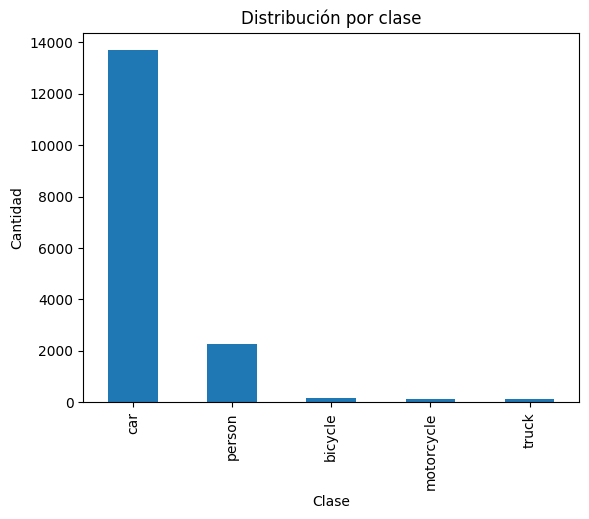

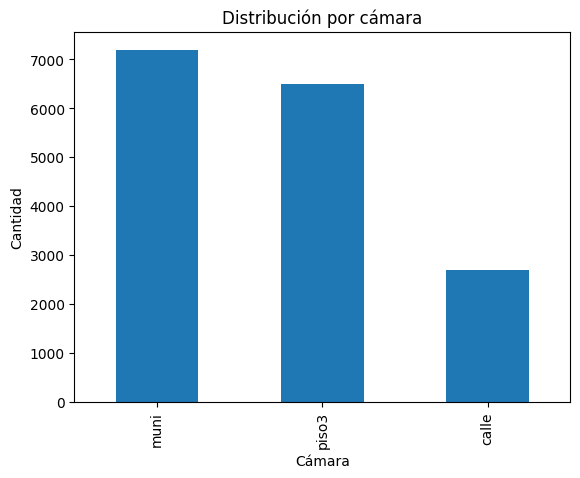

Vehículos rojos: 1143
class
car      1142
truck       1
Name: count, dtype: int64
8.10% de los vehículos detectados fueron clasificados como rojos


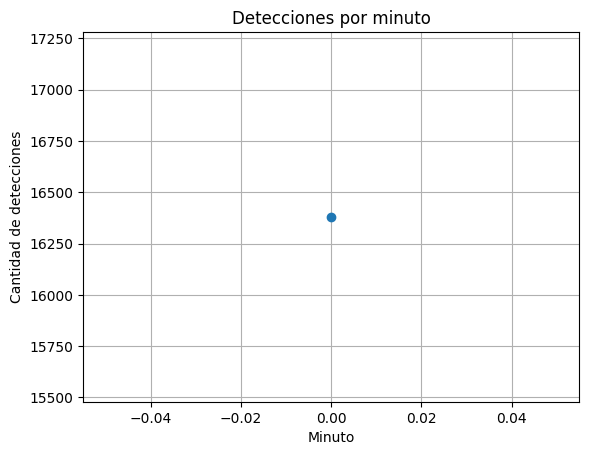

Personas detectadas: 2266
Vehículos detectados: 14114
class   bicycle   car  motorcycle  person  truck
camera                                          
calle         0  2546           0     104     37
muni          0  6517           0     600     82
piso3       182  4624         124    1562      2
Objeto más frecuente: car
Cámara con más detecciones: muni


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

print("Eventos totales:", len(df_total))

if len(df_total) == 0:
    print("⚠️ ADVERTENCIA: El DataFrame 'df_total' está vacío. Por favor, asegúrate de volver a ejecutar las celdas de procesamiento de las cámaras (kJIBPt1nZXa1) y de unificación (uG2tf9rIXKLN) ahora que las rutas de los videos han sido corregidas.")
else:
    print(df_total["class"].value_counts())

    df_total["class"].value_counts().plot(kind="bar")
    plt.title("Distribución por clase")
    plt.xlabel("Clase")
    plt.ylabel("Cantidad")
    plt.show()

    df_total["camera"].value_counts().plot(kind="bar")
    plt.title("Distribución por cámara")
    plt.xlabel("Cámara")
    plt.ylabel("Cantidad")
    plt.show()

    print("Vehículos rojos:", df_total[df_total.is_red].shape[0])
    print(df_total[df_total.is_red]["class"].value_counts())

    vehiculos = ["car", "truck", "motorcycle", "bicycle"]
    df_veh = df_total[df_total["class"].isin(vehiculos)]
    total_veh = len(df_veh)

    if total_veh > 0:
        rojos = len(df_veh[df_veh["is_red"]])
        print(f"{rojos/total_veh*100:.2f}% de los vehículos detectados fueron clasificados como rojos")

    df_total["minuto"] = (df_total["timestamp_s"] // 60).astype(int)
    df_total.groupby("minuto").size().plot(marker="o")
    plt.title("Detecciones por minuto")
    plt.xlabel("Minuto")
    plt.ylabel("Cantidad de detecciones")
    plt.grid()
    plt.show()

    personas = len(df_total[df_total["class"] == "person"])
    print("Personas detectadas:", personas)

    vehiculos_count = len(df_total[df_total["class"].isin(["car","truck","motorcycle","bicycle"])])
    print("Vehículos detectados:", vehiculos_count)

    print(pd.crosstab(df_total["camera"], df_total["class"]))

    objeto_mas_comun = df_total["class"].value_counts().idxmax()
    print("Objeto más frecuente:", objeto_mas_comun)

    camara_mas_activa = df_total["camera"].value_counts().idxmax()
    print("Cámara con más detecciones:", camara_mas_activa)

In [ ]:
print("==== RESUMEN ====")
print("Eventos totales:", len(df_total))
print("Personas:", len(df_total[df_total["class"]=="person"]))
print("Vehículos:", len(df_total[df_total["class"].isin(["car","truck","motorcycle","bicycle"])]))
print("Vehículos rojos:", len(df_total[df_total["is_red"]]))
print("Cámara más activa:", df_total["camera"].value_counts().idxmax())
print("Clase más frecuente:", df_total["class"].value_counts().idxmax())

==== RESUMEN ====
Eventos totales: 16380
Personas: 2266
Vehículos: 14114
Vehículos rojos: 1143
Cámara más activa: muni
Clase más frecuente: car


In [ ]:
#ver los 5 primereos con rojo
df_red = df_total[df_total.is_red]
print("Vehículos rojos detectados:", len(df_red))
df_red.head()

Vehículos rojos detectados: 1143


,timestamp_s,frame,camera,local_id,class,is_red,xc,yc,bw,bh,minuto
543,17.200000,258,calle,5,car,True,0.234788,0.591860,0.028551,0.041595,0
547,17.266667,259,calle,4,car,True,0.231163,0.591277,0.036066,0.049562,0
553,17.333333,260,calle,4,car,True,0.229046,0.587253,0.041044,0.058703,0
561,17.400000,261,calle,5,car,True,0.223362,0.586584,0.052055,0.062962,0
567,17.466667,262,calle,4,car,True,0.221649,0.587883,0.055497,0.060833,0


# Trabajo futuro y transición a la Parte 2

La presente etapa tuvo como objetivo principal validar la adquisición de datos, sincronización de cámaras, detección de objetos, análisis de color y generación de eventos estructurados.

Durante el desarrollo se construyó además un dataset propio compuesto por **588 imágenes etiquetadas manualmente**, que constituye la base para la siguiente fase del proyecto.

Por sugerencia del docente, en la Parte 2 se realizará una evolución del esquema de clasificación vehicular originalmente utilizado.

## Clases empleadas en la Parte 1

- person
- car
- motorcycle
- bicycle
- truck

## Clases objetivo para la Parte 2

- person
- automovil
- utilitario
- pickup
- camion
- motorcycle
- bicycle

Esta reclasificación permitirá entrenar un modelo especializado para tránsito urbano y avanzar hacia un sistema capaz de identificar:

```text
track_id
tipo de vehículo
color